In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [4]:
!wget $data

--2026-10-19 20:24:49--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.005s  

2026-10-19 20:24:49 (53.5 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



In [5]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [6]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [7]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [8]:
df['lead_source'] = df['lead_source'].fillna('NA')
df['industry'] = df['industry'].fillna('NA')
df['employment_status'] = df['employment_status'].fillna('NA')
df['location'] = df['location'].fillna('NA')

df['annual_income'] = df['annual_income'].fillna(0.0)
df['lead_score'] = df['lead_score'].fillna(0.0)

In [9]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [10]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [11]:
len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [12]:
y_train = df_train['converted'].values

In [13]:
from sklearn.metrics import roc_auc_score

features = [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income'
]

for feature in features:
    auc = roc_auc_score(y_train, df_train[feature])
    
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[feature])
        
    print(feature, auc)

lead_score 0.7882254810906102
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
annual_income 0.6081977776250831


In [14]:
y_val = df_val['converted'].values

In [15]:
df_train_model = df_train.drop(columns=['converted'])
df_val_model = df_val.drop(columns=['converted'])

In [16]:
from sklearn.feature_extraction import DictVectorizer

train_dicts = df_train_model.to_dict(orient='records')
val_dicts = df_val_model.to_dict(orient='records')

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [18]:
y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)

round(auc, 3)

0.732

In [19]:
from sklearn.metrics import precision_score, recall_score
import numpy as np

thresholds = np.arange(0.0, 1.01, 0.01)

scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    scores.append((t, precision, recall))

In [20]:
best = None

for t, precision, recall in scores:
    if precision == 0 and recall == 0:
        continue

    difference = abs(precision - recall)

    if best is None or difference < best[0]:
        best = (difference, t, precision, recall)

best

(np.float64(0.007502647993409384),
 np.float64(0.63),
 np.float64(0.7327586206896551),
 np.float64(0.7252559726962458))

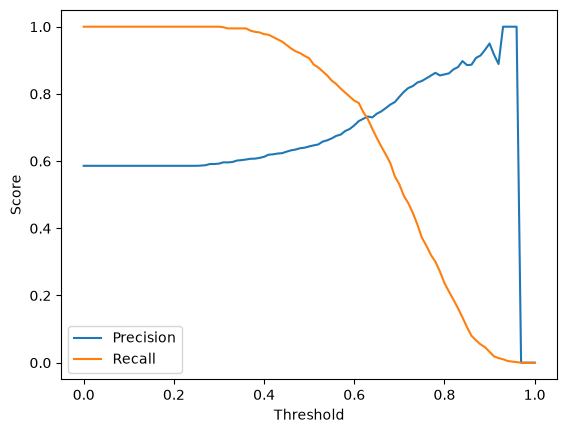

In [21]:
import matplotlib.pyplot as plt

thresholds_plot = [x[0] for x in scores]
precision_plot = [x[1] for x in scores]
recall_plot = [x[2] for x in scores]

plt.plot(thresholds_plot, precision_plot, label='Precision')
plt.plot(thresholds_plot, recall_plot, label='Recall')

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()

In [22]:
f1_scores = []

for t, precision, recall in scores:
    if precision + recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)

    f1_scores.append((t, f1))

In [23]:
max(f1_scores, key=lambda x: x[1])

(np.float64(0.41000000000000003), np.float64(0.7576158940397352))

In [24]:
from sklearn.model_selection import KFold

In [25]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [26]:
def train(df_train, y_train):
    dicts = df_train.to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )
    model.fit(X_train, y_train)

    return dv, model

In [27]:
def predict(df, dv, model):
    dicts = df.to_dict(orient='records')
    X = dv.transform(dicts)

    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [28]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores_cv = []

for train_idx, val_idx in kfold.split(df_full_train):

    df_train_cv = df_full_train.iloc[train_idx].copy()
    df_val_cv = df_full_train.iloc[val_idx].copy()

    y_train_cv = df_train_cv.converted.values
    y_val_cv = df_val_cv.converted.values

    del df_train_cv['converted']
    del df_val_cv['converted']

    dv, model = train(df_train_cv, y_train_cv)
    y_pred_cv = predict(df_val_cv, dv, model)

    auc = roc_auc_score(y_val_cv, y_pred_cv)
    scores_cv.append(auc)

    print(auc)

0.7305601027122453
0.7295726148196622
0.7363428071259397
0.7412454717957564
0.7209138590326581


In [29]:
np.std(scores_cv)

np.float64(0.006853233151022138)

In [30]:
def train(df_train, y_train, C):
    dicts = df_train.to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(
        solver='liblinear',
        C=C,
        max_iter=1000
    )

    model.fit(X_train, y_train)

    return dv, model

In [31]:
C_values = [0.000001, 0.001, 1]

for C in C_values:

    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=1
    )

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):

        df_train_cv = df_full_train.iloc[train_idx].copy()
        df_val_cv = df_full_train.iloc[val_idx].copy()

        y_train_cv = df_train_cv.converted.values
        y_val_cv = df_val_cv.converted.values

        del df_train_cv['converted']
        del df_val_cv['converted']

        dv, model = train(df_train_cv, y_train_cv, C)
        y_pred_cv = predict(df_val_cv, dv, model)

        auc = roc_auc_score(y_val_cv, y_pred_cv)
        scores.append(auc)

    print(C, round(np.mean(scores), 3), round(np.std(scores), 3))

1e-06 0.617 0.019
0.001 0.749 0.01
1 0.732 0.007
